# Importamos librerías

In [1]:
import tensorflow as tf
import pathlib
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import keras

In [2]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dropout, BatchNormalization
from tensorflow.keras.initializers import HeNormal
from keras.regularizers import l1, l2

In [3]:
tf.test.is_gpu_available()

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


False

# Importamos los datos

In [4]:
path = '../../../data/noisy/Campo 50 puntos'

## Datos de entrenamiento

### Datos

In [5]:
campvectrain = np.load(path + '/campvectrain.npy')

In [6]:
np.shape(campvectrain)

(7000, 2, 50, 50)

### Coeficientes

In [7]:
coefcampvectrain = np.load(path + '/coefcampvectrain.npy')

In [8]:
np.shape(coefcampvectrain)

(7000, 7)

## Datos de prueba

### Datos

In [9]:
campvectest = np.load(path + '/campvectest.npy')

In [10]:
np.shape(campvectest)

(2000, 2, 50, 50)

### Coeficientes

In [11]:
coefcampvectest = np.load(path + '/coefcampvectest.npy')

In [12]:
np.shape(coefcampvectest)

(2000, 7)

## Datos de validación

### Datos

In [13]:
campvecval = np.load(path + '/campvecval.npy')

In [14]:
np.shape(campvecval)

(1000, 2, 50, 50)

### Coeficienes

In [15]:
coefcampvecval = np.load(path + '/coefcampvecval.npy')

In [16]:
np.shape(coefcampvecval)

(1000, 7)

# Unimos coeficientes con los datos

In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices((campvectrain, coefcampvectrain))
test_dataset = tf.data.Dataset.from_tensor_slices((campvectest, coefcampvectest))
val_dataset = tf.data.Dataset.from_tensor_slices((campvecval, coefcampvecval))

In [18]:
train_dataset

<TensorSliceDataset element_spec=(TensorSpec(shape=(2, 50, 50), dtype=tf.float64, name=None), TensorSpec(shape=(7,), dtype=tf.int32, name=None))>

# Mezclar y procesar por lotes los conjuntos de datos

In [19]:
BATCH_SIZE = 100
SHUFFLE_BUFFER_SIZE = 100

train_dataset = train_dataset.shuffle(SHUFFLE_BUFFER_SIZE).batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.batch(BATCH_SIZE)

# Creamos función de costo

In [20]:
def custom_loss(y_true, y_pred):
    campvec = []
    # constantes
    a1 = tf.cast(y_true[:, 0], tf.float64)
    #tf.print(a1)
    a1 = tf.reshape(a1, shape=(-1, 1, 1))

    a2 = tf.cast(y_true[:, 1], tf.float64)
    a2 = tf.reshape(a2, shape=(-1, 1, 1))
    
    b1 = tf.cast(y_true[:, 2], tf.float64)
    b1 = tf.reshape(b1,shape = (-1,1,1))
    
    b2 = tf.cast(y_true[:, 3], tf.float64)
    b2 = tf.reshape(b2,shape = (-1,1,1))

    d1 = tf.cast(y_true[:, 4], tf.float64)
    d1 = tf.reshape(d1, shape=(-1, 1, 1))

    d2 = tf.cast(y_true[:, 5], tf.float64)
    d2 = tf.reshape(d2, shape=(-1, 1, 1))

    n = tf.cast(y_true[:, 6], tf.float64)
    n = tf.reshape(n, shape=(-1, 1, 1))

    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        X = tf.cast(X, tf.float64)
        X = tf.reshape(X, shape=(1, 50,50))
        Y = y[1]
        Y = tf.cast(Y, tf.float64)
        Y = tf.reshape(Y, shape=(1, 50,50))
        
        # definimos cada ODE
        dX_dt = tf.divide(a1,(1 + tf.math.pow(Y, n)+1e-5)) - tf.multiply(d1,X) + b1
        dY_dt = tf.divide(a2,(1 + tf.math.pow(X, n)+1e-7)) - tf.multiply(d2,Y) + b2
        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 20
    y_range_neg = 0
    y_range_pos = 20
    y1 = tf.linspace(x_range_neg, x_range_pos, 50)
    y2 = tf.linspace(y_range_neg, y_range_pos, 50)
    Y1, Y2 = tf.meshgrid(y1, y2)
    t = 0
    u, v = tf.zeros(Y1.shape), tf.zeros(Y2.shape)
    u, v = f(t, [Y1, Y2])
    #M = tf.sqrt(tf.square(u) + tf.square(v))
    #u /= M
    #v /= M
# ----------------------------------------------------------------------------
    campvec2 = []
    # constantes
    a12 = tf.cast(y_pred[:, 0], tf.float64)
    a12 = tf.reshape(a12, shape=(-1, 1, 1))

    a22 = tf.cast(y_pred[:, 1], tf.float64)
    a22 = tf.reshape(a22, shape=(-1, 1, 1))
    
    b12 = tf.cast(y_pred[:, 2], tf.float64)
    b12 = tf.reshape(b12,shape = (-1,1,1))
    
    b22 = tf.cast(y_pred[:, 3], tf.float64)
    b22 = tf.reshape(b22,shape = (-1,1,1))

    d12 = tf.cast(y_pred[:, 4], tf.float64)
    d12 = tf.reshape(d12, shape=(-1, 1, 1))

    d22 = tf.cast(y_pred[:, 5], tf.float64)
    d22 = tf.reshape(d22, shape=(-1, 1, 1))

    n2 = tf.cast(y_pred[:, 6], tf.float64)
    n2 = tf.reshape(n2, shape=(-1, 1, 1))
    
    def f2(t2, ye2):

        # asignar a cada ODE a un elemento de vector
        X2 = ye2[0]
        X2 = tf.cast(X2, tf.float64)
        X2 = tf.reshape(X2, shape=(1, 50,50))
        Y2 = ye2[1]
        Y2 = tf.cast(Y2, tf.float64)
        Y2 = tf.reshape(Y2, shape=(1, 50,50))

        # definimos cada ODE
        dX2_dt = tf.divide(a12,(1 + tf.math.pow(Y2, n2)+1e-8)) - tf.multiply(d12,X2) + b12
        dY2_dt = tf.divide(a22,(1 + tf.math.pow(X2, n2)+1e-8)) - tf.multiply(d22,Y2) + b22
        return [dX2_dt, dY2_dt]

    y12 = tf.linspace(x_range_neg, x_range_pos, 50)
    y22 = tf.linspace(y_range_neg, y_range_pos, 50)
    Y12, Y22 = tf.meshgrid(y12, y22)
    u2, v2 = tf.zeros(Y12.shape), tf.zeros(Y22.shape)
    u2, v2 = f2(t, [Y12, Y22])
    #M2 = tf.sqrt(tf.square(u2) + tf.square(v2))
    #u2 /= M2
    #v2 /= M2
    campvecx = tf.abs(tf.subtract(u,u2))
    campvecy = tf.abs(tf.subtract(v,v2))
    campvec_magnitude = tf.add(campvecx,campvecy)
    loss = tf.reduce_mean(campvec_magnitude)
    #tf.print(y_pred)
    return loss

# Creación del modelo

In [21]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [24]:

model = Sequential()
model.add(Flatten(input_shape=(2,50,50)))
model.add(BatchNormalization())
model.add(Dense(128,activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(64,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(128,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(64,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(128,activation = 'tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(64,activation = 'tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))

model.add(Dense(7, activation= custom_activation))

In [25]:

model = Sequential()
model.add(Flatten(input_shape=(2,50,50)))
model.add(BatchNormalization())
model.add(Dense(128,activation='relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(64,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(128,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(64,activation = 'relu',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dropout(0.3))
model.add(Dense(128,activation = 'tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))
model.add(Dense(64,activation = 'tanh',kernel_initializer=HeNormal(), kernel_regularizer=l1(0.001)))

model.add(Dense(7, activation= custom_activation))

In [22]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, BatchNormalization, Flatten
from tensorflow.keras.regularizers import l1, l2

# Initialize the model
model = Sequential()

# Flatten layer
model.add(Flatten(input_shape=(2, 50, 50)))

# First Dense Layer
model.add(Dense(118, activation='relu', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Batch Normalization after first dense layer

# Second Dense Layer
model.add(Dense(54, activation='tanh', kernel_initializer='HeNormal', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())  # Batch Normalization after second dense layer

# Third Dense Layer
model.add(Dense(112, activation='relu', kernel_initializer='random_normal', kernel_regularizer=l1(0.001)))

# Output Dense Layer
model.add(Dense(7, activation=custom_activation))

# Display the model's architecture
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 5000)              0         
                                                                 
 dense (Dense)               (None, 118)               590118    
                                                                 
 batch_normalization (BatchN  (None, 118)              472       
 ormalization)                                                   
                                                                 
 dense_1 (Dense)             (None, 54)                6426      
                                                                 
 batch_normalization_1 (Batc  (None, 54)               216       
 hNormalization)                                                 
                                                                 
 dense_2 (Dense)             (None, 112)               6

In [23]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 5000)              0         
                                                                 
 dense (Dense)               (None, 118)               590118    
                                                                 
 batch_normalization (BatchN  (None, 118)              472       
 ormalization)                                                   
                                                                 
 dense_1 (Dense)             (None, 54)                6426      
                                                                 
 batch_normalization_1 (Batc  (None, 54)               216       
 hNormalization)                                                 
                                                                 
 dense_2 (Dense)             (None, 112)               6

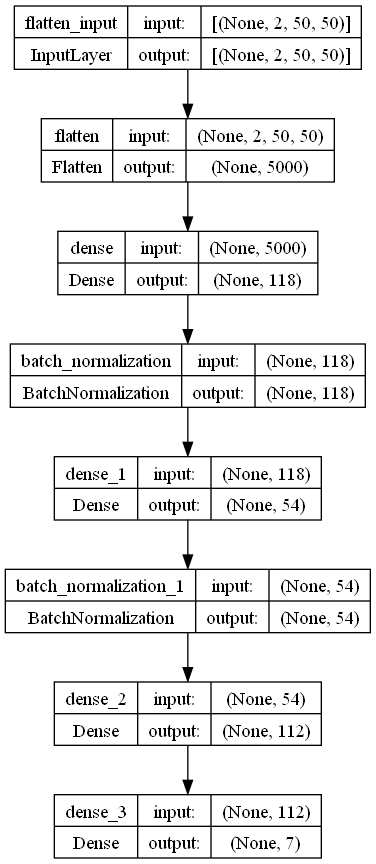

In [24]:
keras.utils.plot_model(model,show_shapes=True)

# Entrenamos el modelo

In [25]:
from keras.optimizers import Adam
optimizer = Adam(learning_rate=0.001,clipvalue=100.0)

In [27]:
def total_mae_loss(y_true, y_pred):
    total_loss = 0
    num_parameters = 7
    for i in range(num_parameters):
        total_loss += tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])
    tf.print(y_true, summarize = -1)
    tf.print(y_pred, summarize = -1)
    return total_loss / num_parameters

In [28]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [29]:
model.compile(optimizer=optimizer,
              loss= custom_loss,
              metrics=metrics)

In [26]:
def scheduler(epoch, lr):
  if epoch < 400:
    return lr
  else:
    return -1.65e-6*epoch +  0.00166

def adaptive_learning_rate(epoch):
    initial_lr = 0.001
    final_lr = 0.0001  # Updated final learning rate
    start_decay_epoch = 100
    end_decay_epoch = 10000
    
    if epoch < start_decay_epoch:
        return initial_lr
    elif epoch >= start_decay_epoch and epoch <= end_decay_epoch:
        lr_range = initial_lr - final_lr
        decay_epochs = end_decay_epoch - start_decay_epoch
        decay_per_epoch = lr_range / decay_epochs
        return initial_lr - (epoch - start_decay_epoch) * decay_per_epoch
    else:
        return final_lr

In [30]:
val_epochs = 1000

early_stop = tf.keras.callbacks.EarlyStopping( monitor = 'val_loss', patience = 100,verbose = 1, 
                                              restore_best_weights = True)

reduce_lr = tf.keras.callbacks.LearningRateScheduler(adaptive_learning_rate)
history = model.fit(train_dataset, validation_data=val_dataset, epochs= val_epochs, callbacks=[reduce_lr, early_stop])

Epoch 1/1000
70/70 [==============================] - 3s 21ms/step - loss: 20.7841 - a_1: 2.5912 - a_2: 2.6790 - b_1: 2.5207 - b_2: 2.6048 - d_1: 1.0631 - d_2: 1.0934 - n: 1.6312 - mean_metric: 0.4439 - val_loss: 24.5373 - val_a_1: 2.5277 - val_a_2: 2.5966 - val_b_1: 2.6040 - val_b_2: 2.6730 - val_d_1: 1.2563 - val_d_2: 1.2031 - val_n: 1.5774 - val_mean_metric: 0.4535 - lr: 0.0010
Epoch 2/1000
70/70 [==============================] - 1s 16ms/step - loss: 17.0631 - a_1: 2.4857 - a_2: 2.5763 - b_1: 2.4058 - b_2: 2.5186 - d_1: 0.8938 - d_2: 0.8790 - n: 1.4872 - mean_metric: 0.4147 - val_loss: 20.2116 - val_a_1: 2.5074 - val_a_2: 2.5219 - val_b_1: 2.4301 - val_b_2: 2.4736 - val_d_1: 1.1566 - val_d_2: 0.9099 - val_n: 1.4876 - val_mean_metric: 0.4237 - lr: 0.0010
Epoch 3/1000
70/70 [==============================] - 1s 16ms/step - loss: 16.5905 - a_1: 2.4712 - a_2: 2.5321 - b_1: 2.2149 - b_2: 2.2934 - d_1: 0.8760 - d_2: 0.8435 - n: 1.4898 - mean_metric: 0.3982 - val_loss: 17.1765 - val_a_1: 

70/70 [==============================] - 1s 16ms/step - loss: 13.5092 - a_1: 2.1627 - a_2: 2.1881 - b_1: 1.1861 - b_2: 1.2412 - d_1: 0.6893 - d_2: 0.6737 - n: 1.4917 - mean_metric: 0.3016 - val_loss: 18.5702 - val_a_1: 2.2042 - val_a_2: 2.1677 - val_b_1: 1.2030 - val_b_2: 1.9931 - val_d_1: 0.8537 - val_d_2: 1.0904 - val_n: 1.4161 - val_mean_metric: 0.3432 - lr: 0.0010
Epoch 23/1000
70/70 [==============================] - 1s 16ms/step - loss: 13.4605 - a_1: 2.1270 - a_2: 2.1403 - b_1: 1.1980 - b_2: 1.2003 - d_1: 0.6811 - d_2: 0.6768 - n: 1.4881 - mean_metric: 0.2978 - val_loss: 15.1184 - val_a_1: 2.1320 - val_a_2: 2.0293 - val_b_1: 1.3034 - val_b_2: 1.4861 - val_d_1: 0.7219 - val_d_2: 0.8288 - val_n: 1.4001 - val_mean_metric: 0.3110 - lr: 0.0010
Epoch 24/1000
70/70 [==============================] - 1s 16ms/step - loss: 13.5656 - a_1: 2.1246 - a_2: 2.1317 - b_1: 1.2015 - b_2: 1.2231 - d_1: 0.6906 - d_2: 0.6779 - n: 1.4894 - mean_metric: 0.2986 - val_loss: 17.2658 - val_a_1: 2.1699 - va

70/70 [==============================] - 1s 16ms/step - loss: 12.8918 - a_1: 1.8038 - a_2: 1.8003 - b_1: 1.0685 - b_2: 1.1143 - d_1: 0.6419 - d_2: 0.6468 - n: 1.4379 - mean_metric: 0.2665 - val_loss: 14.4256 - val_a_1: 1.8169 - val_a_2: 1.8133 - val_b_1: 1.0183 - val_b_2: 1.1987 - val_d_1: 0.7248 - val_d_2: 0.7364 - val_n: 1.4294 - val_mean_metric: 0.2745 - lr: 0.0010
Epoch 44/1000
70/70 [==============================] - 1s 16ms/step - loss: 12.7535 - a_1: 1.7626 - a_2: 1.7906 - b_1: 1.0685 - b_2: 1.1366 - d_1: 0.6386 - d_2: 0.6351 - n: 1.4345 - mean_metric: 0.2651 - val_loss: 13.2414 - val_a_1: 1.8070 - val_a_2: 1.7491 - val_b_1: 1.0964 - val_b_2: 1.2128 - val_d_1: 0.6711 - val_d_2: 0.6693 - val_n: 1.4136 - val_mean_metric: 0.2707 - lr: 0.0010
Epoch 45/1000
70/70 [==============================] - 1s 16ms/step - loss: 12.8995 - a_1: 1.7926 - a_2: 1.7787 - b_1: 1.0957 - b_2: 1.1106 - d_1: 0.6487 - d_2: 0.6387 - n: 1.4334 - mean_metric: 0.2661 - val_loss: 15.4393 - val_a_1: 1.7657 - va

70/70 [==============================] - 1s 17ms/step - loss: 12.3408 - a_1: 1.6316 - a_2: 1.6769 - b_1: 1.0101 - b_2: 1.0698 - d_1: 0.6136 - d_2: 0.6055 - n: 1.3490 - mean_metric: 0.2491 - val_loss: 16.3019 - val_a_1: 1.7207 - val_a_2: 1.7670 - val_b_1: 1.0128 - val_b_2: 1.5146 - val_d_1: 0.8090 - val_d_2: 0.8631 - val_n: 1.3122 - val_mean_metric: 0.2828 - lr: 0.0010
Epoch 65/1000
70/70 [==============================] - 1s 16ms/step - loss: 12.3335 - a_1: 1.6444 - a_2: 1.6680 - b_1: 1.0143 - b_2: 1.0674 - d_1: 0.6093 - d_2: 0.6081 - n: 1.3512 - mean_metric: 0.2493 - val_loss: 14.7090 - val_a_1: 1.6519 - val_a_2: 1.7592 - val_b_1: 1.1800 - val_b_2: 1.1926 - val_d_1: 0.7532 - val_d_2: 0.7155 - val_n: 1.3574 - val_mean_metric: 0.2705 - lr: 0.0010
Epoch 66/1000
70/70 [==============================] - 1s 17ms/step - loss: 12.2315 - a_1: 1.6096 - a_2: 1.6780 - b_1: 1.0286 - b_2: 1.0553 - d_1: 0.6079 - d_2: 0.5992 - n: 1.3468 - mean_metric: 0.2481 - val_loss: 16.5491 - val_a_1: 1.8906 - va

70/70 [==============================] - 1s 16ms/step - loss: 12.1500 - a_1: 1.5472 - a_2: 1.6150 - b_1: 0.9707 - b_2: 1.0550 - d_1: 0.5929 - d_2: 0.5958 - n: 1.3213 - mean_metric: 0.2410 - val_loss: 14.2657 - val_a_1: 1.5557 - val_a_2: 1.4994 - val_b_1: 1.1725 - val_b_2: 1.4650 - val_d_1: 0.7028 - val_d_2: 0.7383 - val_n: 1.3033 - val_mean_metric: 0.2651 - lr: 0.0010
Epoch 86/1000
70/70 [==============================] - 1s 16ms/step - loss: 11.8544 - a_1: 1.5341 - a_2: 1.5739 - b_1: 0.9868 - b_2: 1.0078 - d_1: 0.5812 - d_2: 0.5777 - n: 1.3138 - mean_metric: 0.2372 - val_loss: 18.0461 - val_a_1: 1.6460 - val_a_2: 1.7063 - val_b_1: 1.2907 - val_b_2: 1.4870 - val_d_1: 0.9220 - val_d_2: 0.9413 - val_n: 1.3025 - val_mean_metric: 0.2920 - lr: 0.0010
Epoch 87/1000
70/70 [==============================] - 1s 16ms/step - loss: 11.8188 - a_1: 1.5311 - a_2: 1.5738 - b_1: 0.9658 - b_2: 1.0384 - d_1: 0.5803 - d_2: 0.5737 - n: 1.3205 - mean_metric: 0.2374 - val_loss: 13.9878 - val_a_1: 1.5926 - va

70/70 [==============================] - 1s 16ms/step - loss: 12.0222 - a_1: 1.5234 - a_2: 1.5574 - b_1: 0.9614 - b_2: 1.0563 - d_1: 0.5840 - d_2: 0.5866 - n: 1.2941 - mean_metric: 0.2369 - val_loss: 14.6663 - val_a_1: 1.5658 - val_a_2: 1.4935 - val_b_1: 0.9951 - val_b_2: 1.2384 - val_d_1: 0.7248 - val_d_2: 0.7069 - val_n: 1.2866 - val_mean_metric: 0.2516 - lr: 9.9955e-04
Epoch 107/1000
70/70 [==============================] - 1s 17ms/step - loss: 11.7896 - a_1: 1.5257 - a_2: 1.5660 - b_1: 0.9583 - b_2: 1.0306 - d_1: 0.5728 - d_2: 0.5723 - n: 1.2789 - mean_metric: 0.2350 - val_loss: 15.0231 - val_a_1: 1.5540 - val_a_2: 1.4902 - val_b_1: 1.0516 - val_b_2: 1.0588 - val_d_1: 0.7387 - val_d_2: 0.7227 - val_n: 1.2894 - val_mean_metric: 0.2484 - lr: 9.9945e-04
Epoch 108/1000
70/70 [==============================] - 1s 16ms/step - loss: 11.7072 - a_1: 1.4855 - a_2: 1.5370 - b_1: 0.9656 - b_2: 1.0147 - d_1: 0.5653 - d_2: 0.5715 - n: 1.2845 - mean_metric: 0.2324 - val_loss: 13.2309 - val_a_1: 1

70/70 [==============================] - 1s 16ms/step - loss: 11.4033 - a_1: 1.5010 - a_2: 1.5005 - b_1: 0.9656 - b_2: 1.0020 - d_1: 0.5524 - d_2: 0.5489 - n: 1.2700 - mean_metric: 0.2298 - val_loss: 14.3350 - val_a_1: 1.8272 - val_a_2: 1.4058 - val_b_1: 1.4623 - val_b_2: 1.0772 - val_d_1: 0.7075 - val_d_2: 0.6930 - val_n: 1.3205 - val_mean_metric: 0.2669 - lr: 9.9764e-04
Epoch 128/1000
70/70 [==============================] - 1s 16ms/step - loss: 11.3188 - a_1: 1.4747 - a_2: 1.5136 - b_1: 0.9254 - b_2: 1.0129 - d_1: 0.5448 - d_2: 0.5468 - n: 1.2742 - mean_metric: 0.2283 - val_loss: 18.5822 - val_a_1: 1.6624 - val_a_2: 1.5696 - val_b_1: 1.0840 - val_b_2: 1.3758 - val_d_1: 0.9484 - val_d_2: 0.9372 - val_n: 1.2649 - val_mean_metric: 0.2779 - lr: 9.9755e-04
Epoch 129/1000
70/70 [==============================] - 1s 16ms/step - loss: 11.4536 - a_1: 1.5095 - a_2: 1.5385 - b_1: 0.9464 - b_2: 1.0156 - d_1: 0.5528 - d_2: 0.5509 - n: 1.2585 - mean_metric: 0.2308 - val_loss: 15.6937 - val_a_1: 1

70/70 [==============================] - 1s 16ms/step - loss: 11.3076 - a_1: 1.4846 - a_2: 1.5185 - b_1: 0.9132 - b_2: 1.0109 - d_1: 0.5426 - d_2: 0.5417 - n: 1.2655 - mean_metric: 0.2278 - val_loss: 13.8058 - val_a_1: 1.4653 - val_a_2: 1.3904 - val_b_1: 1.2032 - val_b_2: 1.2402 - val_d_1: 0.6951 - val_d_2: 0.6711 - val_n: 1.2683 - val_mean_metric: 0.2492 - lr: 9.9573e-04
Epoch 149/1000
70/70 [==============================] - 1s 16ms/step - loss: 11.2309 - a_1: 1.4775 - a_2: 1.5306 - b_1: 0.9648 - b_2: 1.0066 - d_1: 0.5404 - d_2: 0.5359 - n: 1.2572 - mean_metric: 0.2289 - val_loss: 15.0569 - val_a_1: 1.5221 - val_a_2: 1.5066 - val_b_1: 1.3967 - val_b_2: 1.6563 - val_d_1: 0.7083 - val_d_2: 0.7808 - val_n: 1.2769 - val_mean_metric: 0.2779 - lr: 9.9564e-04
Epoch 150/1000
70/70 [==============================] - 1s 16ms/step - loss: 11.1478 - a_1: 1.4789 - a_2: 1.5126 - b_1: 0.9433 - b_2: 0.9987 - d_1: 0.5396 - d_2: 0.5287 - n: 1.2615 - mean_metric: 0.2274 - val_loss: 14.8190 - val_a_1: 1

70/70 [==============================] - 1s 16ms/step - loss: 10.7920 - a_1: 1.4733 - a_2: 1.5216 - b_1: 0.9233 - b_2: 0.9994 - d_1: 0.5161 - d_2: 0.5102 - n: 1.2192 - mean_metric: 0.2243 - val_loss: 15.3942 - val_a_1: 1.8765 - val_a_2: 1.5882 - val_b_1: 1.2435 - val_b_2: 1.3068 - val_d_1: 0.7012 - val_d_2: 0.7514 - val_n: 1.2387 - val_mean_metric: 0.2735 - lr: 9.9382e-04
Epoch 170/1000
70/70 [==============================] - 1s 16ms/step - loss: 10.9926 - a_1: 1.4894 - a_2: 1.5317 - b_1: 0.9329 - b_2: 0.9932 - d_1: 0.5255 - d_2: 0.5191 - n: 1.2214 - mean_metric: 0.2258 - val_loss: 17.6470 - val_a_1: 1.9110 - val_a_2: 2.2152 - val_b_1: 1.0712 - val_b_2: 1.9632 - val_d_1: 0.8879 - val_d_2: 0.8985 - val_n: 1.2717 - val_mean_metric: 0.3210 - lr: 9.9373e-04
Epoch 171/1000
70/70 [==============================] - 1s 16ms/step - loss: 10.9878 - a_1: 1.4715 - a_2: 1.5187 - b_1: 0.9150 - b_2: 0.9895 - d_1: 0.5221 - d_2: 0.5276 - n: 1.2307 - mean_metric: 0.2246 - val_loss: 16.7278 - val_a_1: 1

# Analizamos accuracy y loss

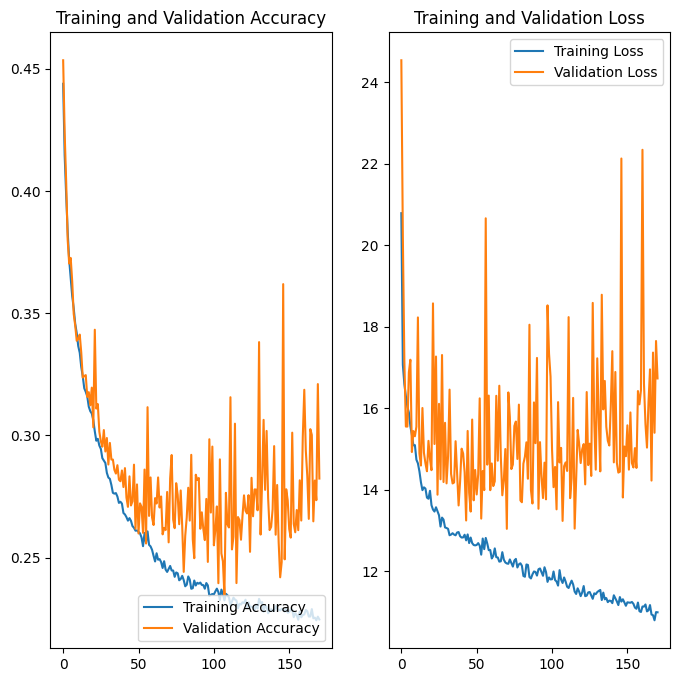

In [31]:
acc = history.history['mean_metric']
val_acc = history.history['val_mean_metric']

loss = history.history['loss']
val_loss = history.history['val_loss']

#epochs_range = range(val_epochs)
epochs_range = range(171)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

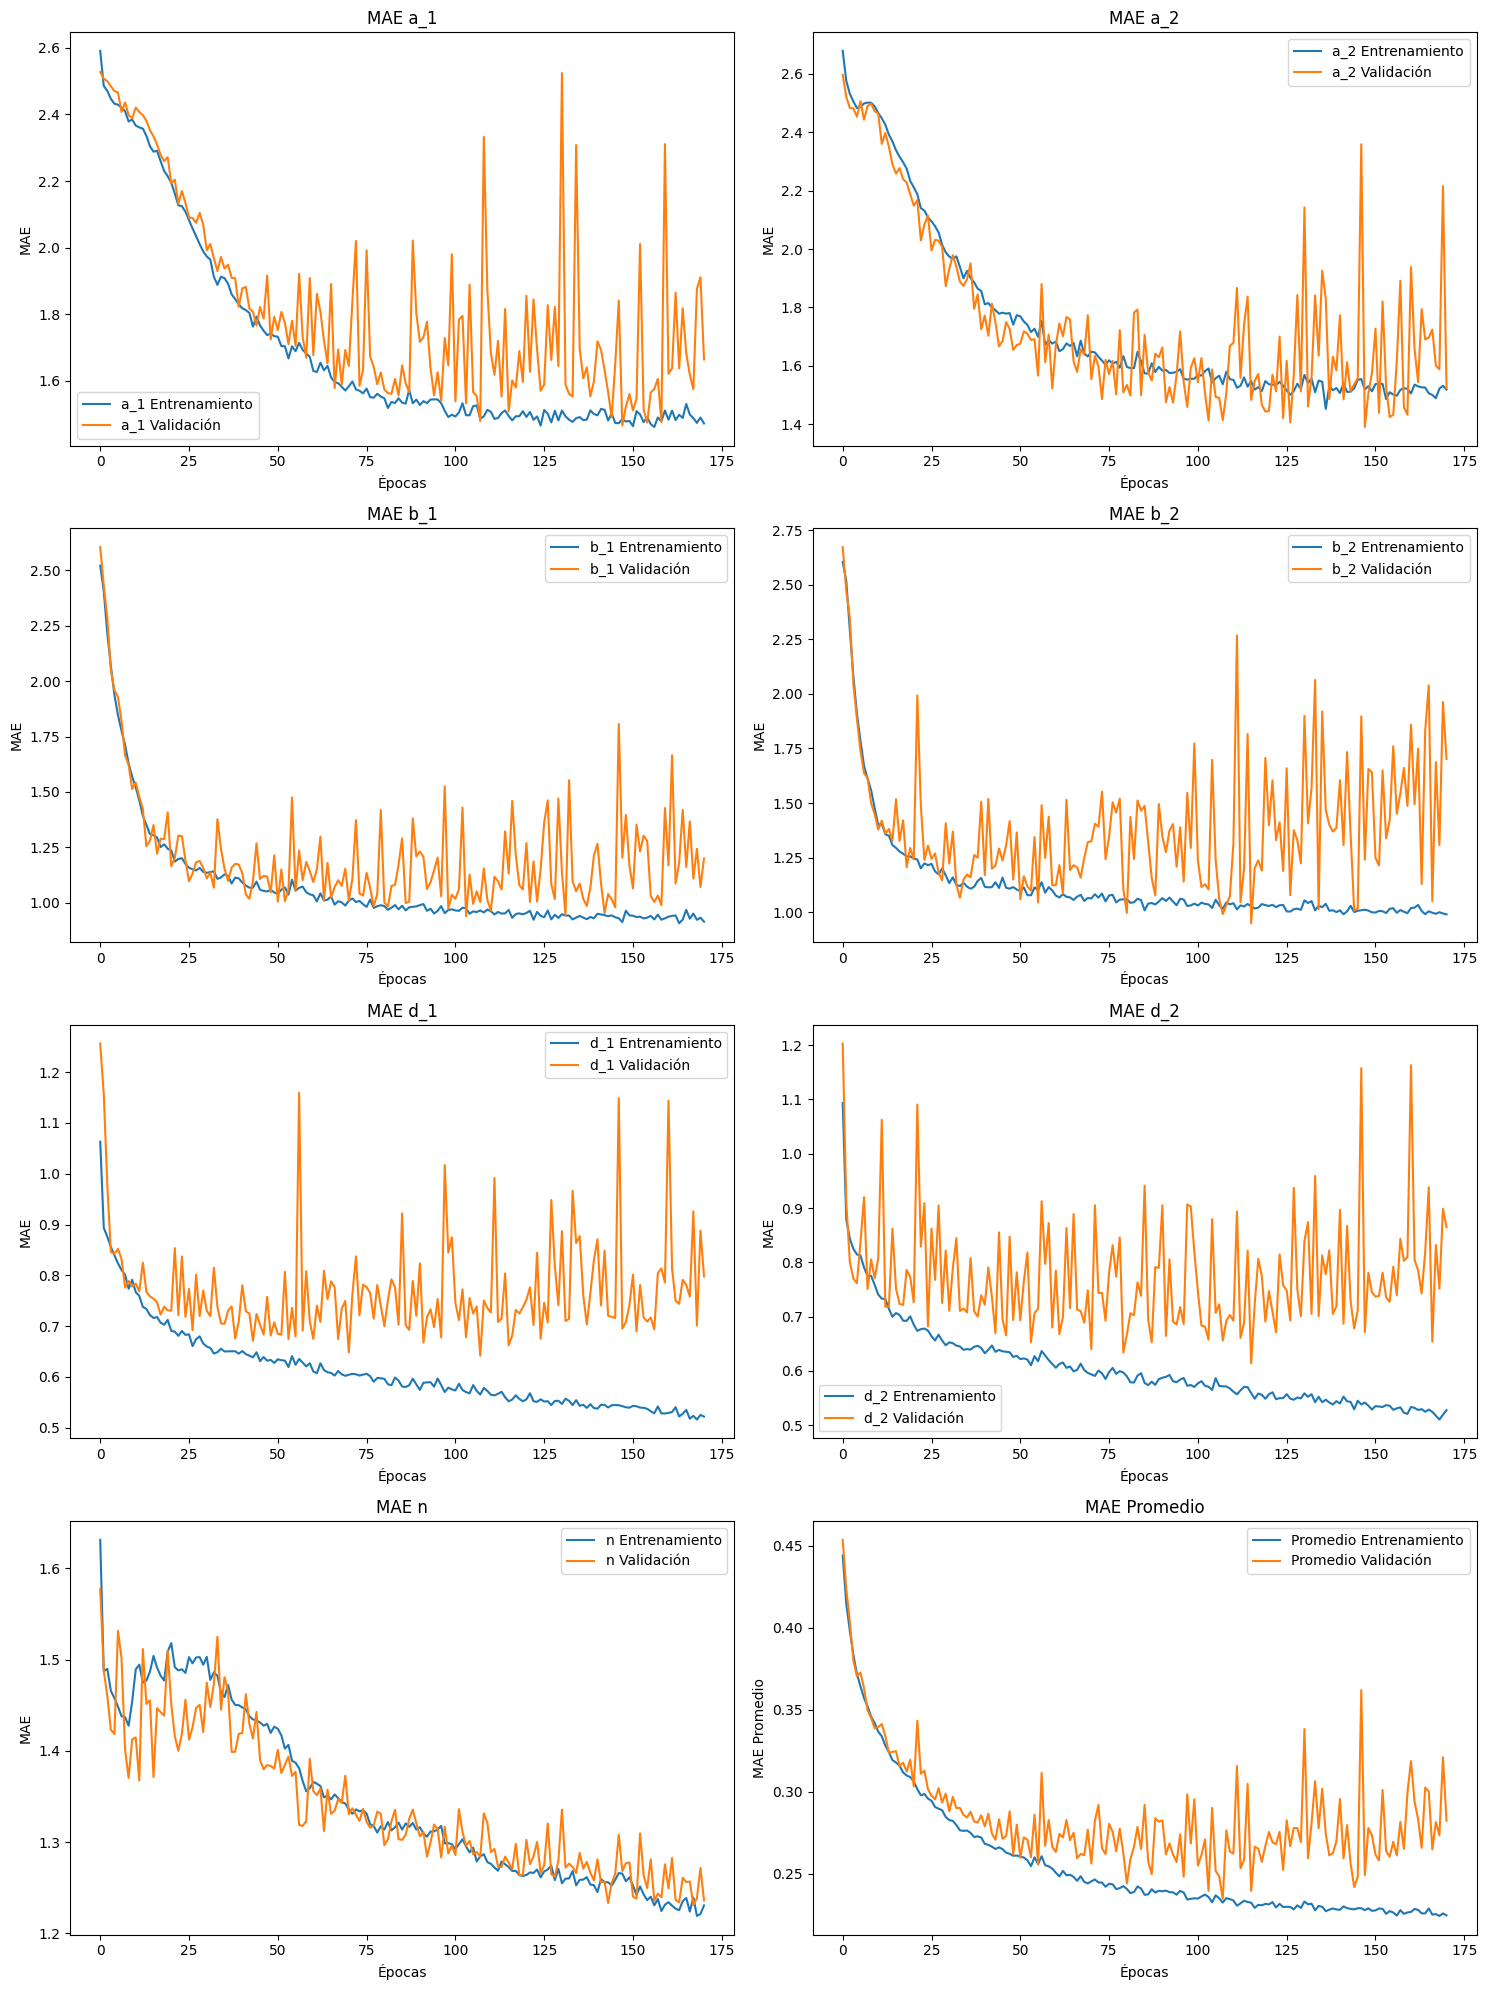

In [32]:
# Número de coeficientes más uno para la métrica adicional
n_coef = len(coeficientesnombres) + 1

# Número de filas y columnas para los subplots
n_rows = (n_coef + 1) // 2
n_cols = 2

# Crear una figura más grande para acomodar todos los subplots
plt.figure(figsize=(15, 5 * n_rows))

# Crear un subplot para cada coeficiente
for i, name in enumerate(coeficientesnombres):
    plt.subplot(n_rows, n_cols, i + 1)
    plt.plot(history.history[name ], label=name + ' Entrenamiento')
    plt.plot(history.history['val_' + name ], label=name + ' Validación')
    plt.title('MAE ' + name)
    plt.xlabel('Épocas')
    plt.ylabel('MAE')
    plt.legend()

# Agregar un subplot para la métrica prom_per
plt.subplot(n_rows, n_cols, n_coef)
plt.plot(history.history['mean_metric'], label='Promedio Entrenamiento')
plt.plot(history.history['val_mean_metric'], label='Promedio Validación')
plt.title('MAE Promedio')
plt.xlabel('Épocas')
plt.ylabel('MAE Promedio')
plt.legend()

# Ajustar el diseño para asegurarse de que todo encaje bien
plt.tight_layout()
plt.show()

# Evaluamos el modelo

In [33]:
test_loss, test_a1, test_a2, test_b1, test_b2, test_d1, test_d2, test_n, testprom_per = model.evaluate(
    campvectest, coefcampvectest)

63/63 [==============================] - 0s 2ms/step - loss: 13.6371 - a_1: 1.6412 - a_2: 1.5962 - b_1: 1.0429 - b_2: 1.3391 - d_1: 0.6856 - d_2: 0.6766 - n: 1.3322 - mean_metric: 0.2607


In [34]:
predictions = model.predict(campvectest)

63/63 [==============================] - 0s 707us/step


In [35]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Calcula el MAE
mae = mean_absolute_error(coefcampvectest, predictions)

# Calcula la desviación estándar del error
error = coefcampvectest - predictions
std_dev = np.std(error)

# Calcula el error absoluto máximo
max_error = np.max(np.abs(error))

print(f"MAE: {mae}, Desviación estándar del error: {std_dev}, Error absoluto máximo: {max_error}")

MAE: 1.1875226651992914, Desviación estándar del error: 1.571229164468159, Error absoluto máximo: 7.039484024047852


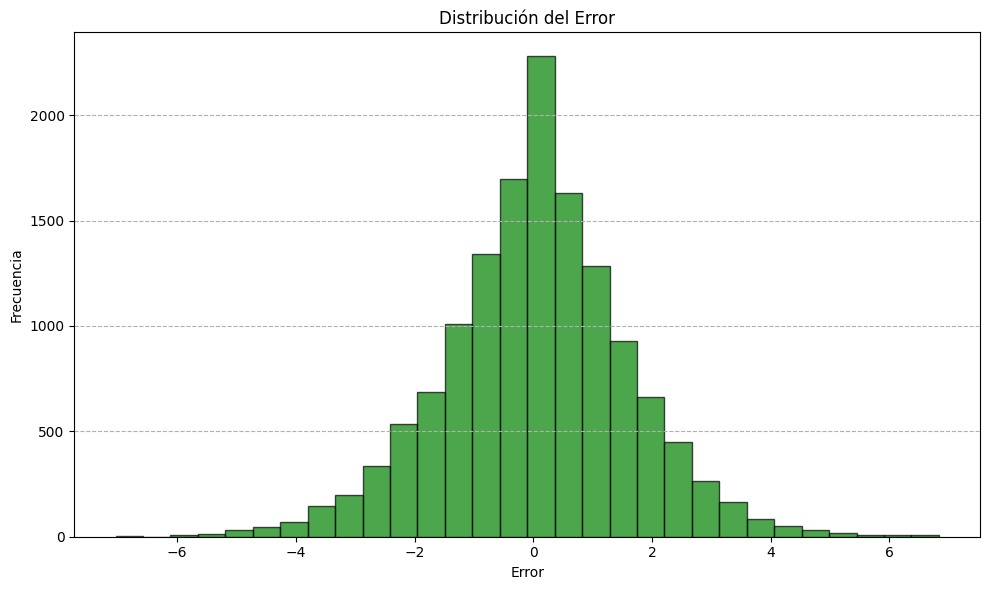

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(error.flatten(), bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error')  # Añade un título al gráfico
plt.xlabel('Error')  # Etiqueta el eje x
plt.ylabel('Frecuencia')  # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

In [37]:
# Calcula el error absoluto para cada dato
absolute_error = np.abs(coefcampvectest - predictions)

# Calcula el error para cada dato
error = coefcampvectest - predictions

# Calcula la suma de los valores reales para cada dato
sum_real_values = np.sum(coefcampvectest, axis=-1)

# Divide el error absoluto por la suma de los valores reales para cada dato
relative_error_per_data = np.sum(absolute_error, axis=-1) / sum_real_values

# Calcula el MAE relativo como la media de los errores relativos
relative_mae = np.mean(relative_error_per_data)

# Divide el error por la suma de los valores reales para cada dato
relative_error_per_data_std_max = np.sum(error, axis=-1) / sum_real_values

# Calcula la desviación estándar del error relativo
relative_std_dev = np.std(relative_error_per_data_std_max)

# Calcula el error absoluto máximo relativo
relative_max_error = np.max(np.abs(relative_error_per_data_std_max))

print(f"MAE relativo: {relative_mae}")
print(f"Desviación estándar del error relativo: {relative_std_dev}")
print(f"Error absoluto máximo relativo: {relative_max_error}")

MAE relativo: 0.2667299949715764
Desviación estándar del error relativo: 0.23198657299239758
Error absoluto máximo relativo: 1.56472422555089


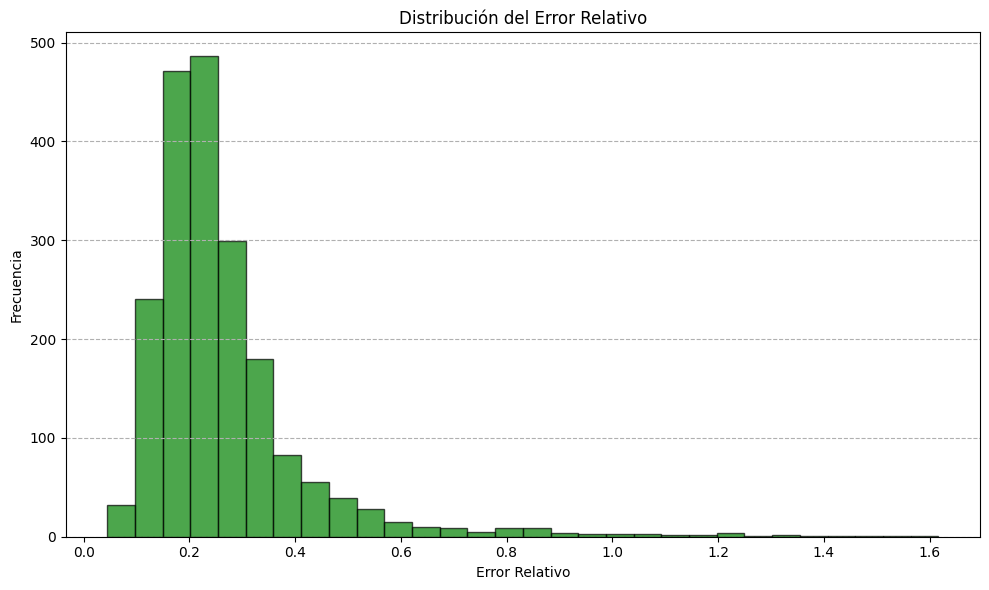

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))  # Establece el tamaño del gráfico
plt.hist(relative_error_per_data, bins=30, edgecolor='black', alpha=0.7, color = 'green')  # Añade bordes negros a las barras y ajusta la transparencia
plt.title('Distribución del Error Relativo')  # Añade un título al gráfico
plt.xlabel('Error Relativo')  # Etiqueta el eje x
plt.ylabel('Frecuencia')      # Etiqueta el eje y
plt.grid(axis='y', linestyle='--')  # Añade una cuadrícula horizontal
plt.tight_layout()  # Ajusta el diseño para evitar que se recorten las etiquetas
plt.show()

# Guardamos los datos de Accuracy y Loss

In [39]:
df = pd.DataFrame.from_dict(history.history)
df.to_csv('../../../Gráficas finales con ruido/grid50_traj100/historycampvec50costo.csv', index = False)

# Guardamos el modelo

In [40]:
path_to_save = '../../../trained_models_noisy/grid50_traj100'

In [41]:
model.save(path_to_save + '/campovectorial50funcioncosto.h5')

# Importamos el modelo

In [42]:
def custom_activation(x):
    return 10 * tf.nn.sigmoid(x)

In [43]:
coeficientesnombres = ('a_1', 'a_2', 'b_1', 'b_2', 'd_1', 'd_2', 'n')

def mse_component(i):
    def mse_i(y_true, y_pred):
        return tf.keras.losses.mean_absolute_error(y_true[:, i], y_pred[:, i])

    mse_i.__name__ = coeficientesnombres[i]
    return mse_i

def mean_metric(y_true, y_pred):
    total_loss = 0
    for i in range(7):
        total_loss += mse_component(i)(y_true, y_pred)
    sum_of_true_coefficients = tf.reduce_sum(y_true, axis=-1)
    return total_loss / sum_of_true_coefficients

metrics = [mse_component(i) for i in range(7)] + [mean_metric]

In [44]:
import keras
import tensorflow as tf
# Creación de un diccionario con todas las métricas personalizadas
custom_objects = {'custom_loss':custom_loss,'custom_activation':custom_activation,'mean_metric': mean_metric}
for i in range(7):
    custom_objects[coeficientesnombres[i]] = mse_component(i)
new_model = keras.models.load_model('../../../trained_models_noisy/grid50_traj100/campovectorial50funcioncosto.h5', 
                                    custom_objects=custom_objects)

# Probamos el modelo con datos nuevos

## Creamos nuevos datos

In [48]:
import random 
import matplotlib.pyplot as plt
for i in range(0, 1):
    # constantes
    a1 = random.randint(1, 10)
    a2 = random.randint(1, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(1, 5)

    coef = [a1, a2, b1, b2, d1, d2, n]

    for i_ci in range(0, 1):
        x_range_neg = 0
        x_range_pos = 10
        y_range_neg = 0
        y_range_pos =10

        y1 = np.linspace(x_range_neg, x_range_pos, 50)
        y2 = np.linspace(y_range_neg, y_range_pos, 50)

        Y1, Y2 = np.meshgrid(y1, y2)

        t1 = 0

        NI, NJ = Y1.shape
        u, v = np.zeros((NI, NJ)), np.zeros((NI, NJ))

        for i in range(NI):
            for j in range(NJ):
                # asignar a cada ODE a un elemento de vector
                X = Y1[i, j]
                Y = Y2[i, j]
                noise1 = np.random.normal(0, .5)
                noise2 = np.random.normal(0, .5)

                # definimos cada ODE
                dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
                dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2

                u[i, j], v[i, j] = dX_dt, dY_dt

        M = (np.hypot(u, v))
        u1, v1 = u, v
        u /= M
        v /= M

    campvecci = np.append([u], [v], axis=0)

    campvec = campvecci
    print(coef)

    
campvec = np.array(campvec)
coef = np.array(coef)


[6, 1, 0, 1, 1, 1, 2]


In [49]:
campvecnone = campvec[None, :]

## Predecimos con los datos nuevos

In [50]:
new_predictions = new_model.predict(campvecnone)
new_predictions = np.round(new_predictions)
new_predictions = np.clip(new_predictions, 0, None)
print(new_predictions)

1/1 [==============================] - 0s 11ms/step
[[10.  1.  1.  2.  1.  1.  6.]]


## Encontramos puntos de equilibrio datos reales

In [52]:
from scipy.optimize import fsolve
# Sistema de ecuaciones
def system(Y):
    X, Y = Y
    dX_dt = a1/(1+Y**n)-d1*X+b1
    dY_dt = a2/(1+X**n)-d2*Y+b2
    return [dX_dt, dY_dt]

# Adivinanza inicial para X, Y
initial_guess = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_reales = fsolve(system, initial_guess)
primer_cuadrante_reales = tuple(primer_cuadrante_reales)


print(primer_cuadrante_reales)

(2.648976129942531, 1.1247337785593672)


## Graficamos con los coeficientes reales

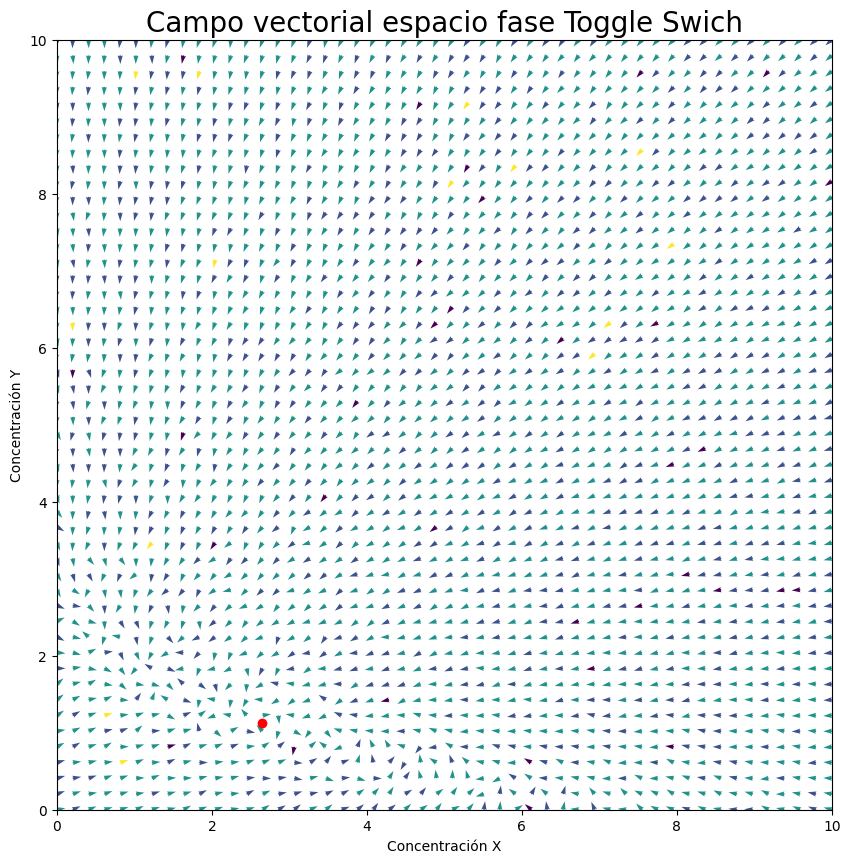

In [53]:
import matplotlib.pyplot as plt

x_values = primer_cuadrante_reales[0]
y_values =primer_cuadrante_reales[1]

y1 = np.linspace(0, 10, 50)
y2 = np.linspace(0, 10, 50)
Y1, Y2 = np.meshgrid(y1, y2)
t1 = 0
u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)
NI, NJ = Y1.shape        
u,v = np.array(campvec)[0,:,:], np.array(campvec)[1,:,:]
M = (np.hypot(u,v))
u /= M
v /= M

plt.figure(figsize=(10,10))
Q = plt.quiver(Y1, Y2, u, v, M, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.scatter(x_values, y_values, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')
plt.show()

## Encontramos puntos de equilibrio datos pedecidos

In [54]:
a1pred = new_predictions[0,0]
a2pred = new_predictions[0,1]
b1pred = new_predictions[0,2]
b2pred = new_predictions[0,3]
d1pred = new_predictions[0,4]
d2pred = new_predictions[0,5]
npred = new_predictions[0,6]

def systempred(Ypred):
    Xpred, Ypred = Ypred
    dXpred_dt = a1pred/(1+Ypred**npred)-d1pred*Xpred+b1pred
    dYpred_dt = a2pred/(1+Xpred**npred)-d2pred*Ypred+b2pred
    return [dXpred_dt, dYpred_dt]

# Adivinanza inicial para X, Y
initial_guesspred = [0, 0]

# Encontrar los puntos de equilibrio
primer_cuadrante_predecidos = fsolve(systempred, initial_guesspred)
primer_cuadrante_predecidos = tuple(primer_cuadrante_predecidos)


print(primer_cuadrante_predecidos)

(1.0483823288400322, 2.429598359216185)


## Graficamos con los coeficientes predecidos

Text(0, 0.5, 'Concentración Y')

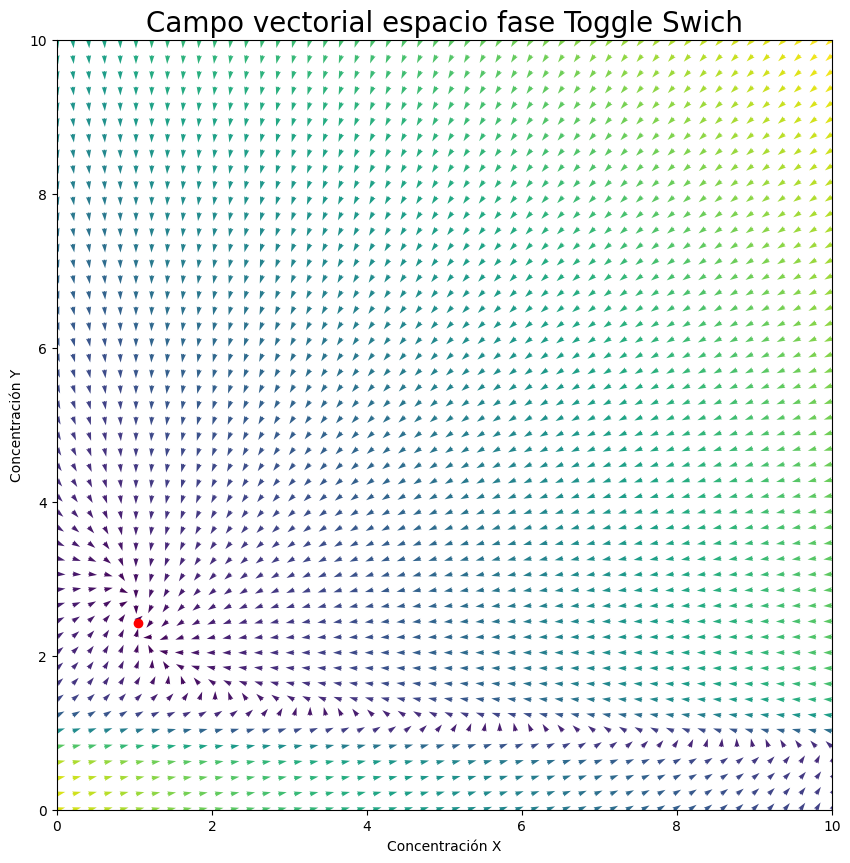

In [55]:
import matplotlib.pyplot as plt

def f(t, y):

    # asignar a cada ODE a un elemento de vector
    X = y[0]
    Y = y[1]

    # definimos cada ODE
    dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
    dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

    return [dX_dt, dY_dt]

x_range_neg = 0
x_range_pos = 10
y_range_neg = 0
y_range_pos = 10

y1pred = np.linspace(x_range_neg, x_range_pos, 50)
y2pred = np.linspace(y_range_neg, y_range_pos, 50)

Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
t1 = 0

upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

NI, NJ = Y1.shape

u1pred, v1pred = f(t1, [Y1, Y2])
upred, vpred = f(t1, [Y1, Y2])
Mpred = (np.hypot(upred, vpred))
upred /= Mpred
vpred /= Mpred


x_valuespred = primer_cuadrante_predecidos[0]
y_valuespred =primer_cuadrante_predecidos[1]
plt.figure(figsize=(10, 10))
Q = plt.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy')
plt.title('Campo vectorial espacio fase Toggle Swich', fontsize=20)
plt.xlim([x_range_neg, x_range_pos])
plt.ylim([y_range_neg, y_range_pos])
plt.scatter(x_valuespred, y_valuespred, color='red')  # Puedes cambiar el color como prefieras
plt.xlabel('Concentración X')
plt.ylabel('Concentración Y')

## Graficamos ambos

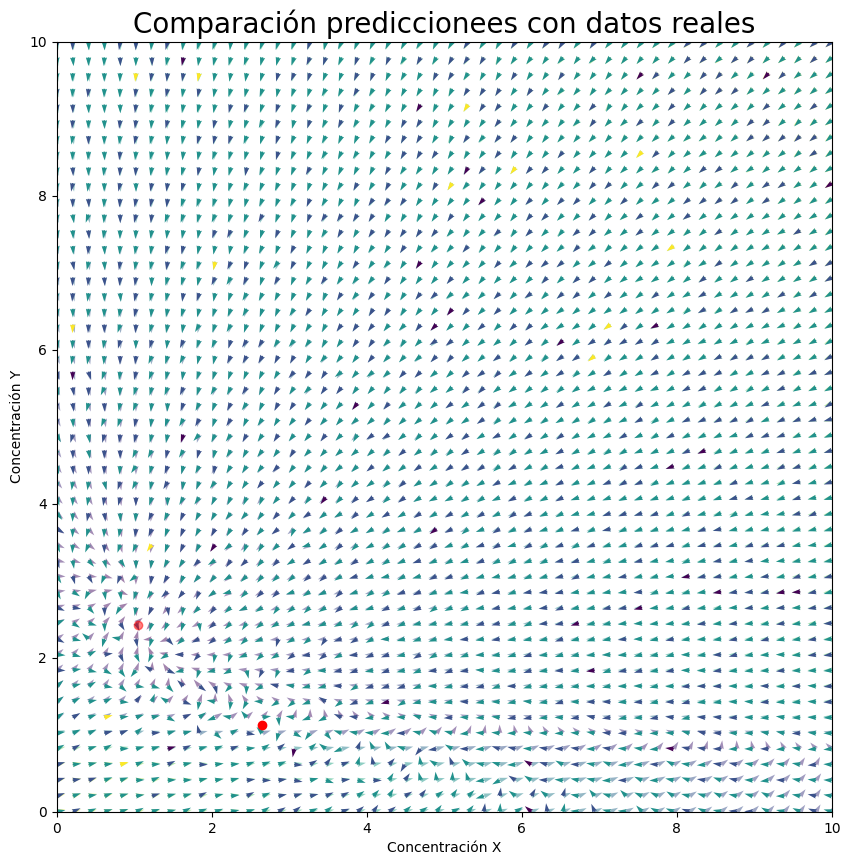

In [56]:
fig, ax = plt.subplots(figsize=(10, 10))

# Primero graficamos la predicción, que debería ser más clara (alpha < 1)
Q = ax.quiver(Y1, Y2, upred, vpred, Mpred, angles='xy', alpha=0.5)

# Luego, graficamos los datos originales, que serán más oscuros (alpha = 1)
Q1 = ax.quiver(Y1, Y2, u, v, M, angles='xy', alpha=1)

ax.scatter(x_valuespred, y_valuespred, color='red', alpha = 0.5)
ax.scatter(x_values, y_values, color='red', alpha = 1)
ax.set_title('Comparación prediccionees con datos reales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

plt.show()

## Graficamos las diferencias

59.99883093993707


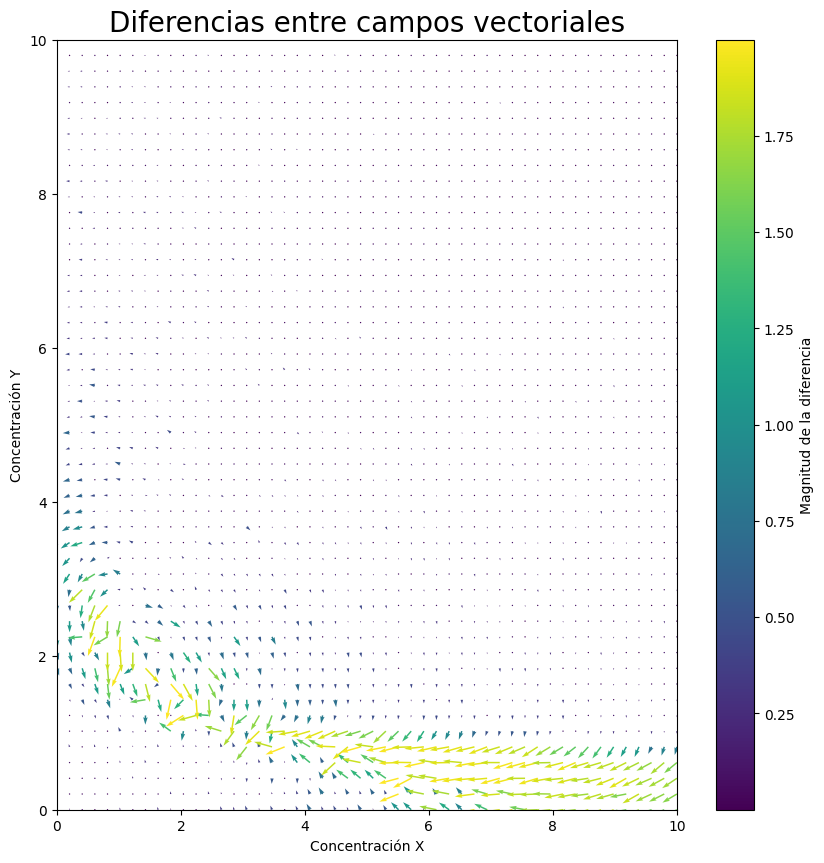

In [57]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7
u_diff2 = u_diff + epsilon
v_diff2 = v_diff + epsilon

# Ahora calculamos la magnitud
#M_diff = np.hypot(u_diff2, v_diff2)
M_diff = np.hypot(u_diff, v_diff)

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30
print(rango)
# Escala para las flechas. Aumenta este valor si las flechas son demasiado grandes.
scale = 70

# Graficamos las diferencias
#Q = ax.quiver(Y1, Y2, u_diff2, v_diff2, M_diff, angles='xy')
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy', scale = rango)
#Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff, angles='xy')


ax.set_title('Diferencias entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia')

plt.show()

## Errores relativos

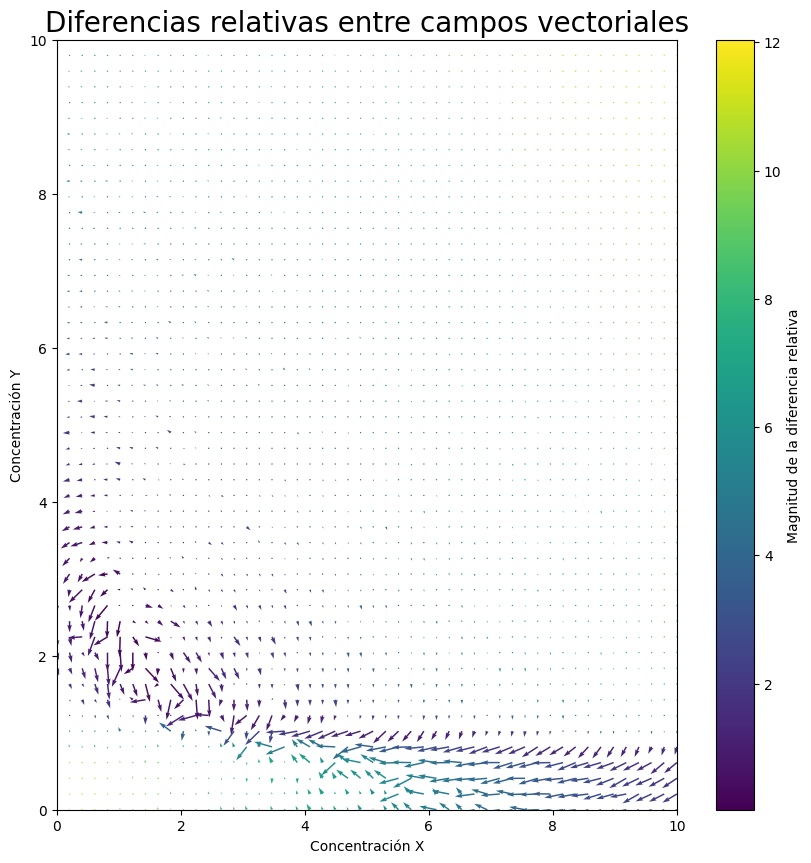

In [58]:
fig, ax = plt.subplots(figsize=(10, 10))

# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u1, v1) + epsilon
M_diff = np.hypot(u1pred, v1pred)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

#Calcula la magnitud de los vectores
magnitudes = np.sqrt(u_diff**2 + v_diff**2)

# Calcula el rango de las magnitudes
rango = (np.max(magnitudes) - np.min(magnitudes))*30

# Graficamos las diferencias relativas
Q = ax.quiver(Y1, Y2, u_diff, v_diff, M_diff_rel, angles='xy', scale = rango)

ax.set_title('Diferencias relativas entre campos vectoriales', fontsize=20)
ax.set_xlim([0, 10])
ax.set_ylim([0, 10])
ax.set_xlabel('Concentración X')
ax.set_ylabel('Concentración Y')

# Creamos una leyenda para la magnitud de las flechas
cbar = plt.colorbar(Q, ax=ax)
cbar.set_label('Magnitud de la diferencia relativa')

plt.show()

In [59]:
# Calculamos las diferencias
u_diff = u - upred
v_diff = v - vpred

# Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
epsilon = 1e-7

# Calculamos la magnitud del vector original y de la diferencia
M_orig = np.hypot(u, v) + epsilon
M_diff = np.hypot(u_diff, v_diff)

# Calculamos la diferencia relativa
M_diff_rel = M_diff / M_orig

# Aplicamos el filtro para la diferencia relativa mayor a 0.05
mask = M_diff_rel > 0.05

# Calculamos el porcentaje de puntos que cumplen con la condición
porcentaje = np.mean(mask) * 100

print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 es {porcentaje:.2f}%")

El porcentaje de puntos cuyo error relativo es mayor a 0.05 es 72.52%


## Simulamos n veces

In [61]:
import numpy as np
import random
from scipy.optimize import fsolve

# Listas para almacenar los resultados
porcentajes = []

# Repetimos el proceso 10 veces
for repetir in range(10000):
    campvec = []
    coef = []
    # constantes
    a1 = random.randint(0, 10)
    a2 = random.randint(0, 10)
    b1 = random.randint(0, 10)
    b2 = random.randint(0, 10)
    d1 = random.randint(0, 10)
    d2 = random.randint(0, 10)
    n = random.randint(0, 5)

    coef1 = [a1, a2, b1, b2, d1, d2, n]
    coef.append(coef1)

    def ftrue(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1/(1+Y**n)-d1*X+b1
        dY_dt = a2/(1+X**n)-d2*Y+b2

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1 = np.linspace(x_range_neg, x_range_pos, 50)
    y2 = np.linspace(y_range_neg, y_range_pos, 50)

    Y1, Y2 = np.meshgrid(y1, y2)
    
    t1 = 0

    u, v = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape
    
    
    for i in range(NI):
        for j in range(NJ):
            # asignar a cada ODE a un elemento de vector
            X = Y1[i, j]
            Y = Y2[i, j]
            noise1 = np.random.normal(0, .5)
            noise2 = np.random.normal(0, .5)
            # definimos cada ODE
            dX_dt=(a1)/(1+Y**(n))-(d1)*X+b1+noise1
            dY_dt=(a2)/(1+X**(n))-(d2)*Y+b2+noise2
            u[i, j], v[i, j] = dX_dt, dY_dt

    M = (np.hypot(u, v))
    u /= M
    v /= M

    campvecci = np.append([u], [v], axis=0)

    campvec = campvecci
    print('--------------------------------------------')
#    print(coef1)
    
    campvec = np.array(campvec)

    
    campvecnone = campvec[None, :]
    
    new_predictions = new_model.predict(campvecnone)
    new_predictions = np.round(new_predictions)
    new_predictions = np.clip(new_predictions, 0, None)
#    print(new_predictions)
    
    
    a1pred = new_predictions[0,0]
    a2pred = new_predictions[0,1]
    b1pred = new_predictions[0,2]
    b2pred = new_predictions[0,3]
    d1pred = new_predictions[0,4]
    d2pred = new_predictions[0,5]
    npred = new_predictions[0,6]
    
    def f(t, y):

        # asignar a cada ODE a un elemento de vector
        X = y[0]
        Y = y[1]

        # definimos cada ODE
        dX_dt = a1pred/(1+Y**npred)-d1pred*X+b1pred
        dY_dt = a2pred/(1+X**npred)-d2pred*Y+b2pred

        return [dX_dt, dY_dt]

    x_range_neg = 0
    x_range_pos = 10
    y_range_neg = 0
    y_range_pos = 10

    y1pred = np.linspace(x_range_neg, x_range_pos, 50)
    y2pred = np.linspace(y_range_neg, y_range_pos, 50)

    Y1pred, Y2pred = np.meshgrid(y1pred, y2pred)
    
    t1 = 0

    upred, vpred = np.zeros(Y1pred.shape), np.zeros(Y2pred.shape)

    NI, NJ = Y1.shape

    u1pred, v1pred = f(t1, [Y1, Y2])
    upred, vpred = f(t1, [Y1, Y2])
    Mpred = (np.hypot(upred, vpred))
    upred /= Mpred
    vpred /= Mpred
    
    utrue, vtrue = np.zeros(Y1.shape), np.zeros(Y2.shape)

    NI, NJ = Y1.shape

    utrue, vtrue = ftrue(t1, [Y1, Y2])
    Mtrue = (np.hypot(utrue, vtrue))
    utrue /= Mtrue
    vtrue /= Mtrue  

 # Calculamos las diferencias
    u_diff = utrue - upred
    v_diff = vtrue - vpred

    # Aseguramos que ningún vector tenga una magnitud exactamente igual a cero
    epsilon = 1e-7

    # Calculamos la magnitud del vector original y de la diferencia
    M_orig = np.hypot(u, v) + epsilon
    M_diff = np.hypot(u_diff, v_diff)

    # Calculamos la diferencia relativa
    M_diff_rel = M_diff / M_orig

    # Aplicamos el filtro para la diferencia relativa mayor a 0.05
    mask = M_diff_rel > 0.05

    # Calculamos el porcentaje de puntos que cumplen con la condición
    porcentaje = np.mean(mask) * 100

    # Almacenamos el resultado en la lista
    porcentajes.append(porcentaje)

    print(f"El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración {repetir+1} es {porcentaje:.2f}%")

# Muestra todos los porcentajes al final
print("Porcentajes para las 10 iteraciones:", porcentajes)

# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")


--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 1 es 82.84%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 2 es 4.76%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 3 es 42.52%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 4 es 75.68%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 5 es 54.96%
--------------------------------------------
1/1 [==========================

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 45 es 13.56%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 46 es 20.64%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 47 es 15.12%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 48 es 27.16%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 49 es 13.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de p

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 89 es 84.16%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 90 es 45.40%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 91 es 54.00%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 92 es 7.00%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 93 es 52.32%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de pu

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 133 es 15.28%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 134 es 34.52%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 135 es 20.76%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 136 es 10.76%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 137 es 5.64%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje 

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 177 es 14.80%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 178 es 78.64%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 179 es 22.08%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 180 es 29.24%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 181 es 37.96%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 221 es 20.48%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 222 es 48.48%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 223 es 86.76%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 224 es 71.36%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 225 es 29.28%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje

... (218 outputs left out)

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9784 es 19.72%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9785 es 21.96%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9786 es 18.40%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9787 es 50.68%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9788 es 17.00%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porce

--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9828 es 23.32%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9829 es 67.96%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9830 es 49.60%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9831 es 14.80%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9832 es 45.08%
--------------------------------------------
1/1 [==========

1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9872 es 30.36%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9873 es 22.88%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9874 es 10.84%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9875 es 69.16%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9876 es 11.68%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porce

1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9916 es 7.92%
--------------------------------------------
1/1 [==============================] - 0s 11ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9917 es 26.92%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9918 es 2.32%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9919 es 37.36%
--------------------------------------------
1/1 [==============================] - 0s 12ms/step
El porcentaje de puntos cuyo error relativo es mayor a 0.05 en la iteración 9920 es 24.80%
--------------------------------------------
1/1 [==============================] - 0s 10ms/step
El porcent

El promedio de los porcentajes es 41.99%


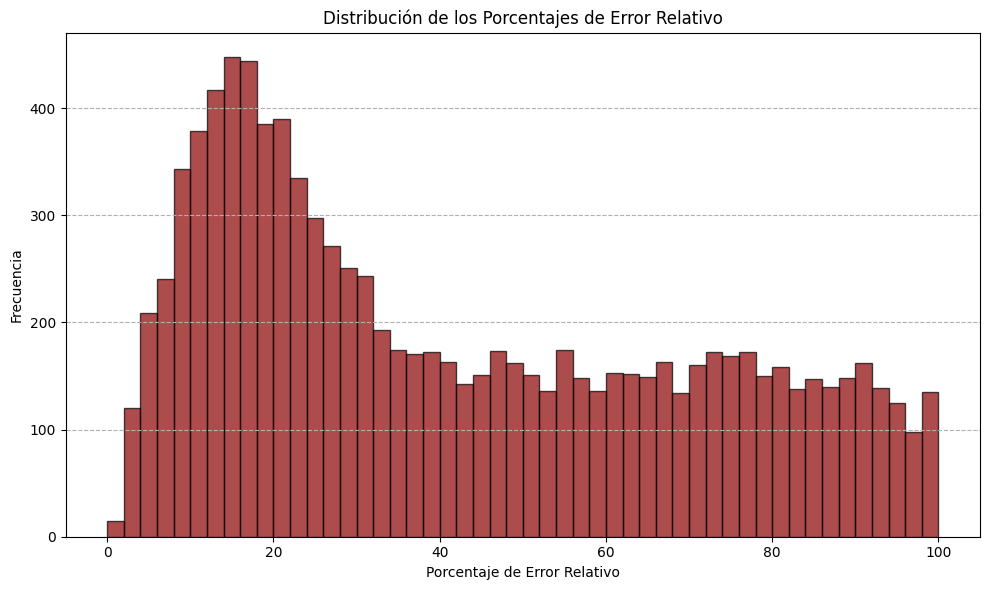

In [62]:
import matplotlib.pyplot as plt

# ...

# Muestra todos los porcentajes al final
# Calcula y muestra el promedio de los porcentajes
promedio = np.mean(porcentajes)
print(f"El promedio de los porcentajes es {promedio:.2f}%")

# Crea un histograma de los porcentajes
plt.figure(figsize=(10, 6))
plt.hist(porcentajes, bins=50, edgecolor='black', alpha=0.7, color = 'darkred')
plt.title('Distribución de los Porcentajes de Error Relativo')
plt.xlabel('Porcentaje de Error Relativo')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--')
plt.tight_layout()
plt.show()